=== PASO 1: CARGA Y LIMPIEZA DE DATOS PRIMARIA===

=== EVALUANDO 4 MODELOS EN EL CONJUNTO DE PRUEBA ===
Entrenando DecisionTreeClassifier...
  -> DecisionTreeClassifier completado con éxito.
Entrenando RandomForestClassifier...
  -> RandomForestClassifier completado con éxito.
Entrenando KNeighborsClassifier...
  -> KNeighborsClassifier completado con éxito.
Entrenando HistGradientBoosting (LGBM Equivalent)...
  -> HistGradientBoosting (LGBM Equivalent) completado con éxito.

TABLA COMPARATIVA DE MODELOS PARA LA TESIS PRIMARIA (ORDENADOS POR AUC-PR)
                                Modelo  Accuracy  Precision  Recall  F1-Score  AUC-ROC  AUC-PR
HistGradientBoosting (LGBM Equivalent)    0.9959     0.9100  0.9505    0.9298   0.9881  0.9530
                RandomForestClassifier    0.9962     0.9192  0.9500    0.9343   0.9878  0.9526
                  KNeighborsClassifier    0.9875     0.7101  0.9485    0.8122   0.9742  0.8560
                DecisionTreeClassifier    0.9909     0.7989  0.9

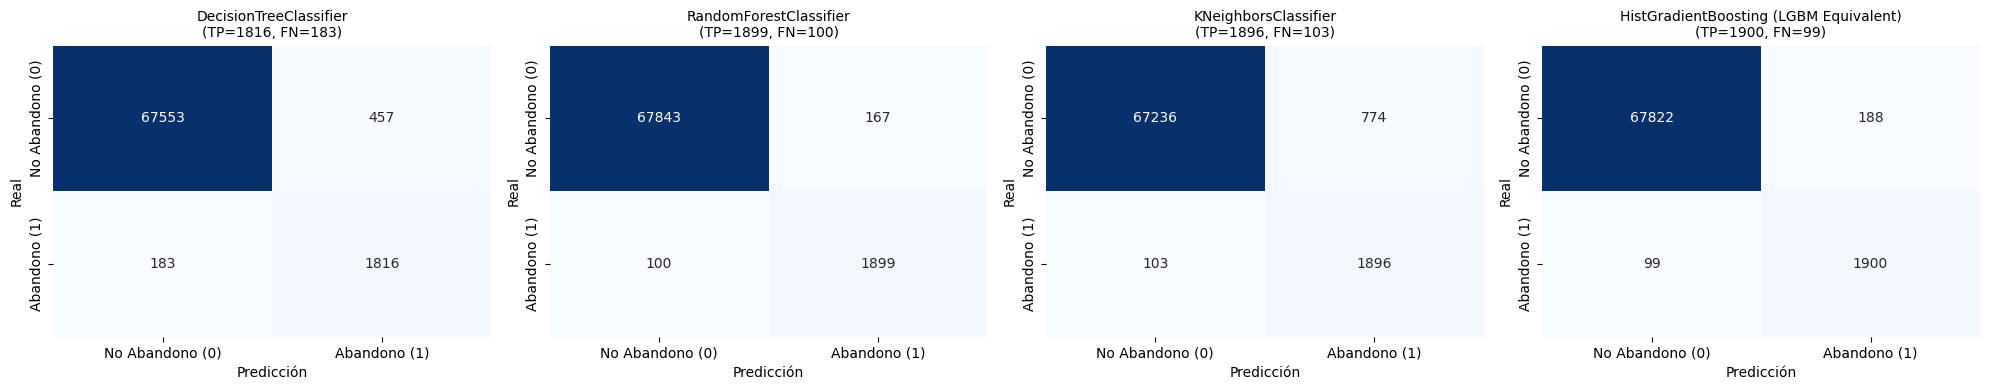


[OK] El mejor modelo 'HistGradientBoosting (LGBM Equivalent)' y sus artefactos han sido guardados en 'modelo_abandono_primaria.pkl'


In [1]:
import pandas as pd
import numpy as np
import joblib #serializar (pickle) y guardar en disco el artefacto final del modelo entrenado y sus metadatos
import matplotlib.pyplot as plt
import seaborn as sns #gráficas estadísticas, visualización de distribuciones y mapas de calor (matrices de confusión)
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split #Función para dividir el dataset en conjuntos independientes de entrenamiento y prueba.
from sklearn.impute import SimpleImputer #Preprocesadores para rellenar valores faltantes (mediante la media) y normalizar la escala de las variables numéricas respectivamente.
from sklearn.preprocessing import StandardScaler #Preprocesadores para rellenar valores faltantes (mediante la media) y normalizar la escala de las variables numéricas respectivamente.
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline #Estructuras secuenciales para encadenar transformadores y estimadores, asegurando que el preprocesamiento y el remuestreo ocurran de forma aislada sin fugas de datos (data leakage).
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix
)
from imblearn.pipeline import Pipeline as ImbPipeline #Estructuras secuenciales para encadenar transformadores y estimadores, asegurando que el preprocesamiento y el remuestreo ocurran de forma aislada sin fugas de datos (data leakage).
from imblearn.over_sampling import SMOTE #Técnica de sobremuestreo sintético de la minoría para balancear las clases en el modelo KNN

def cargar_y_preparar_datos(filepath="trainning_prima.csv"):
    df = pd.read_csv(filepath)
    
    # Excluir identificadores y columnas no numéricas directas
    columnas_excluir = ['curp', 'cct', 'ciclo', 'tipo_movimiento', 'abandono']
    columnas_excluir_existentes = [col for col in columnas_excluir if col in df.columns]
    
    X = df.drop(columns=columnas_excluir_existentes)
    y = df['abandono']
    
    # Forzar conversión estricta a numérico
    for col in X.columns:
        X[col] = pd.to_numeric(X[col], errors='coerce')
        
    numeric_cols = X.select_dtypes(include=['int64', 'float64', 'float32', 'int32']).columns.tolist()
    X = X[numeric_cols]
    
    #Divide los datos reservando un 20% para pruebas. El argumento stratify=y es crucial porque garantiza que tanto el conjunto de entrenamiento como el de prueba mantengan exactamente la misma proporción de alumnos en riesgo de abandono.
    return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y), numeric_cols

def construir_modelos():
    # Usamos HistGradientBoostingClassifier como equivalente exacto de LightGBM optimizado y sin errores de C++ en Windows
    modelos = {
        'DecisionTreeClassifier': Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('clf', DecisionTreeClassifier(random_state=42, class_weight='balanced'))
        ]),
        'RandomForestClassifier': Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('clf', RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, class_weight='balanced', n_jobs=1))
        ]),
        'KNeighborsClassifier': ImbPipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('scaler', StandardScaler()),                 # Escalamos primero (vital para que las distancias de SMOTE y KNN funcionen bien)
            ('smote', SMOTE(random_state=42)),            # Aplicamos SMOTE solo en el set de entrenamiento interno
            ('clf', KNeighborsClassifier(n_neighbors=7, n_jobs=1))
        ]),
        'HistGradientBoosting (LGBM Equivalent)': Pipeline([
            ('imputer', SimpleImputer(strategy='mean')),
            ('clf', HistGradientBoostingClassifier(random_state=42, max_iter=100, class_weight='balanced'))
        ])
    }
    return modelos

def evaluar_experimento():
    print("=== PASO 1: CARGA Y LIMPIEZA DE DATOS PRIMARIA===")
    (X_train, X_test, y_train, y_test), feature_names = cargar_y_preparar_datos()
    
    modelos = construir_modelos()
    resultados = []
    matrices_confusion = {}
    modelos_entrenados = {}

    print(f"\n=== EVALUANDO {len(modelos)} MODELOS EN EL CONJUNTO DE PRUEBA ===")
    
    for nombre, pipeline in modelos.items():
        print(f"Entrenando {nombre}...")
        try:
            pipeline.fit(X_train, y_train)
            
            y_pred = pipeline.predict(X_test)
            y_proba = pipeline.predict_proba(X_test)[:, 1] if hasattr(pipeline, "predict_proba") else y_pred

            acc = accuracy_score(y_test, y_pred)
            prec = precision_score(y_test, y_pred, zero_division=0)
            rec = recall_score(y_test, y_pred, zero_division=0)
            f1 = f1_score(y_test, y_pred, zero_division=0)
            roc_auc = roc_auc_score(y_test, y_proba)
            pr_auc = average_precision_score(y_test, y_proba)
            cm = confusion_matrix(y_test, y_pred)

            resultados.append({
                'Modelo': nombre,
                'Accuracy': round(acc, 4),
                'Precision': round(prec, 4),
                'Recall': round(rec, 4),
                'F1-Score': round(f1, 4),
                'AUC-ROC': round(roc_auc, 4),
                'AUC-PR': round(pr_auc, 4)
            })
            
            matrices_confusion[nombre] = cm
            modelos_entrenados[nombre] = pipeline
            print(f"  -> {nombre} completado con éxito.")
            
        except Exception as e:
            print(f"Error evaluando {nombre}: {e}")

    if not resultados:
        print("No se pudo evaluar ningún modelo.")
        return

    # Tabla resumen ordenada por AUC-PR
    df_resultados = pd.DataFrame(resultados).sort_values(by='AUC-PR', ascending=False).reset_index(drop=True)
    
    print("\n" + "="*80)
    print("TABLA COMPARATIVA DE MODELOS PARA LA TESIS PRIMARIA (ORDENADOS POR AUC-PR)")
    print("="*80)
    print(df_resultados.to_string(index=False))
    
    mejor_modelo_nombre = df_resultados.loc[0, 'Modelo']
    mejor_pipeline = modelos_entrenados[mejor_modelo_nombre]
    
    print("\n" + "="*80)
    print(f"MEJOR MODELO SELECCIONADO: {mejor_modelo_nombre}")
    print(f"   Métricas -> AUC-PR: {df_resultados.loc[0, 'AUC-PR']} | AUC-ROC: {df_resultados.loc[0, 'AUC-ROC']} | Recall: {df_resultados.loc[0, 'Recall']}")
    print("="*80)

    # Graficar Matrices de Confusión
    fig, axes = plt.subplots(1, len(matrices_confusion), figsize=(5 * len(matrices_confusion), 4))
    if len(matrices_confusion) == 1:
        axes = [axes]

    for ax, (nombre, cm) in zip(axes, matrices_confusion.items()):
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                    xticklabels=['No Abandono (0)', 'Abandono (1)'],
                    yticklabels=['No Abandono (0)', 'Abandono (1)'])
        ax.set_title(f'{nombre}\n(TP={cm[1,1]}, FN={cm[1,0]})', fontsize=10)
        ax.set_xlabel('Predicción')
        ax.set_ylabel('Real')

    plt.tight_layout()
    plt.savefig('matrices_confusion_comparativa_primaria.png', dpi=300)
    plt.show()

    # Guardar Artefacto Final
    artefacto_final = {
        'pipeline': mejor_pipeline,
        'features': feature_names,
        'nombre_modelo': mejor_modelo_nombre,
        'metricas_comparativas': df_resultados
    }
    
    output_path = "modelo_abandono_primaria.pkl"
    joblib.dump(artefacto_final, output_path)
    print(f"\n[OK] El mejor modelo '{mejor_modelo_nombre}' y sus artefactos han sido guardados en '{output_path}'")

if __name__ == "__main__":
    evaluar_experimento()

In [2]:
import joblib
artefacto = joblib.load("modelo_abandono.pkl")
print(artefacto['features'])

['turno', 'grado', 'sexo_bin', 'categoroia_poblacion', 'promedio_general', 'parciales_reprobados_b1', 'parciales_reprobados_b2', 'parciales_reprobados_b3', 'calif_bim1', 'calif_bim2', 'calif_bim3', 'faltas_b1', 'faltas_b2', 'faltas_b3', 'faltas_totales', 'materias_repro', 'extra_edad', 'alumno_migrante', 'repetidor', 'necesidad_edu_esp', 'reinscrito']
